<a href="https://colab.research.google.com/github/Kishore-Krish19/ML/blob/main/Transformer_English_French_Translation_Max_accuracy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Connect to google drive

In [1]:
from google.colab import drive
import os

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/Transformer_Translation_Max"
os.makedirs(SAVE_DIR, exist_ok=True)

STAGE1_PATH = os.path.join(
    SAVE_DIR, "stage1_best.weights.h5"
)

STAGE2_PATH = os.path.join(
    SAVE_DIR, "stage2_best.weights.h5"
)

STAGE3_PATH = os.path.join(
    SAVE_DIR, "stage3_best.weights.h5"
)

print("Stage 1:", STAGE1_PATH)
print("Stage 2:", STAGE2_PATH)
print("Stage 3:", STAGE3_PATH)

Mounted at /content/drive
Stage 1: /content/drive/MyDrive/Transformer_Translation_Max/stage1_best.weights.h5
Stage 2: /content/drive/MyDrive/Transformer_Translation_Max/stage2_best.weights.h5
Stage 3: /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5


Environment Setup

In [2]:
!pip -q install datasets tokenizers sacrebleu matplotlib

In [3]:
import tensorflow as tf
import keras

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Keras version: 3.13.2
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Downloading the Dataset

In [4]:
import os
import zipfile
import keras

url = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"

zip_path = keras.utils.get_file(
    fname="fra-eng.zip",
    origin=url,
    extract=False
)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/fra_eng")

print("Dataset downloaded successfully!")
print("Files:", os.listdir("/content/fra_eng"))

3423204/3423204 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset downloaded successfully!
Files: ['fra.txt', '_about.txt']


Reading the dataset

In [5]:
import pathlib

text_file = pathlib.Path("/content/fra_eng/fra.txt")

with open(text_file, encoding="utf-8") as f:
    lines = f.read().splitlines()

text_pairs = []

for line in lines:
    parts = line.split("\t")
    if len(parts) >= 2:
        english = parts[0]
        french = parts[1]
        text_pairs.append((english, french))

print("Total sentence pairs:", len(text_pairs))

print("\nFirst 5 sentence pairs:\n")

for eng, fra in text_pairs[:5]:
    print("English:", eng)
    print("French :", fra)
    print("-" * 40)

Total sentence pairs: 167130

First 5 sentence pairs:

English: Go.
French : Va !
----------------------------------------
English: Hi.
French : Salut !
----------------------------------------
English: Run!
French : Cours !
----------------------------------------
English: Run!
French : Courez !
----------------------------------------
English: Who?
French : Qui ?
----------------------------------------


Visualize dataset sentence length

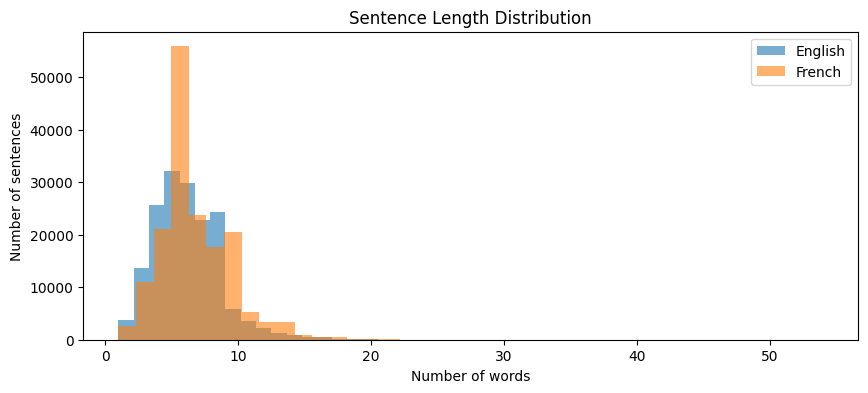

In [6]:
import matplotlib.pyplot as plt

english_lengths = [
    len(eng.split()) for eng, fra in text_pairs
]

french_lengths = [
    len(fra.split()) for eng, fra in text_pairs
]

plt.figure(figsize=(10, 4))

plt.hist(english_lengths, bins=40, alpha=0.6, label="English")
plt.hist(french_lengths, bins=40, alpha=0.6, label="French")

plt.xlabel("Number of words")
plt.ylabel("Number of sentences")
plt.title("Sentence Length Distribution")
plt.legend()
plt.show()

3.1 Prepare and split the dataset

In [7]:
import random
import re

SEED = 42

# Read the complete original dataset.
# Do not reuse a previously shuffled/truncated text_pairs.
with open(text_file, encoding="utf-8") as f:
    lines = f.read().splitlines()

all_pairs = []

for line in lines:
    parts = line.split("\t")

    if len(parts) >= 2:
        english = parts[0].strip()
        french = parts[1].strip()

        if english and french:
            all_pairs.append((english, french))

print("Total original pairs:", len(all_pairs))

# Shuffle reproducibly
rng = random.Random(SEED)
rng.shuffle(all_pairs)

# Group by English source sentence.
# This prevents the same English sentence appearing
# in both training and evaluation datasets.
source_groups = {}

for eng, fra in all_pairs:
    source_groups.setdefault(eng, []).append((eng, fra))

groups = list(source_groups.values())
rng.shuffle(groups)

# Fixed evaluation sets: 3,000 pairs each
val_raw = []
test_raw = []
train_raw = []

for group in groups:
    # Keep groups intact to avoid source-sentence leakage
    if len(val_raw) < 3000:
        val_raw.extend(group)
    elif len(test_raw) < 3000:
        test_raw.extend(group)
    else:
        train_raw.extend(group)

# Stage 1 uses a smaller subset of the training pool
stage1_train_raw = train_raw[:24000]

# Stage 2 and 3 use the expanded training pool
stage2_train_raw = train_raw
stage3_train_raw = train_raw

# Add special tokens exactly once
def add_target_tokens(pairs):
    return [
        (eng, "[start] " + fra + " [end]")
        for eng, fra in pairs
    ]

stage1_train_pairs = add_target_tokens(stage1_train_raw)
stage2_train_pairs = add_target_tokens(stage2_train_raw)
stage3_train_pairs = stage2_train_pairs

val_pairs = add_target_tokens(val_raw)
test_pairs = add_target_tokens(test_raw)

# Verify no English-source leakage
train_sources = {eng for eng, _ in stage2_train_pairs}
val_sources = {eng for eng, _ in val_pairs}
test_sources = {eng for eng, _ in test_pairs}

assert not (train_sources & val_sources)
assert not (train_sources & test_sources)
assert not (val_sources & test_sources)

# Verify special tokens
for dataset in [
    stage1_train_pairs,
    stage2_train_pairs,
    val_pairs,
    test_pairs
]:
    assert all(
        fra.count("[start]") == 1 and
        fra.count("[end]") == 1
        for _, fra in dataset
    )

print("\nSTAGE 1")
print("Training pairs:", len(stage1_train_pairs))

print("\nSTAGE 2")
print("Training pairs:", len(stage2_train_pairs))

print("\nSTAGE 3")
print("Training pairs:", len(stage3_train_pairs))

print("\nFIXED EVALUATION SETS")
print("Validation pairs:", len(val_pairs))
print("Testing pairs:", len(test_pairs))

print("\nDATA LEAKAGE CHECK")
print("Train/Validation overlap:", len(train_sources & val_sources))
print("Train/Test overlap:", len(train_sources & test_sources))
print("Validation/Test overlap:", len(val_sources & test_sources))

print("\nExample training pair:")
print(stage1_train_pairs[0])

Total original pairs: 167130

STAGE 1
Training pairs: 24000

STAGE 2
Training pairs: 161130

STAGE 3
Training pairs: 161130

FIXED EVALUATION SETS
Validation pairs: 3000
Testing pairs: 3000

DATA LEAKAGE CHECK
Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0

Example training pair:
('AI stands for artificial intelligence.', '[start] IA signifie Intelligence Artificielle. [end]')


3.2: Text preprocessing and tokenization

3.2.1 Create the vectorization layers

In [8]:
import tensorflow as tf
import keras
import string
import re

# Remove punctuation but preserve [start] and [end]
strip_chars = string.punctuation + "¿"
strip_chars = strip_chars.replace("[", "").replace("]", "")

def custom_standardization(input_string):
    lowercase = tf.strings.lower(input_string)

    return tf.strings.regex_replace(
        lowercase,
        "[%s]" % re.escape(strip_chars),
        ""
    )

# Same configuration as our previous Transformer
vocab_size = 15000
sequence_length = 20

# English tokenizer
source_vectorization = keras.layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length
)

# French tokenizer
target_vectorization = keras.layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length + 1,
    standardize=custom_standardization
)

# Adapt both tokenizers using the expanded training set
# Never adapt on validation or test data
train_english = [
    eng for eng, fra in stage2_train_pairs
]

train_french = [
    fra for eng, fra in stage2_train_pairs
]

source_vectorization.adapt(train_english)
target_vectorization.adapt(train_french)

print("English vocabulary size:",
      len(source_vectorization.get_vocabulary()))

print("French vocabulary size:",
      len(target_vectorization.get_vocabulary()))

print("\nStart token ID:",
      target_vectorization.get_vocabulary().index("[start]"))

print("End token ID:",
      target_vectorization.get_vocabulary().index("[end]"))

English vocabulary size: 14314
French vocabulary size: 15000

Start token ID: 2
End token ID: 3


3.2.2 Verify tokenization

In [9]:
sample_english = ["I love machine learning."]

sample_french = [
    "[start] j'aime apprendre [end]"
]

english_tokens = source_vectorization(sample_english)
french_tokens = target_vectorization(sample_french)

print("English sentence:", sample_english[0])
print("English token IDs:", english_tokens.numpy()[0])

print("\nFrench sentence:", sample_french[0])
print("French token IDs:", french_tokens.numpy()[0])

print("\nEnglish shape:", english_tokens.shape)
print("French shape:", french_tokens.shape)

English sentence: I love machine learning.
English token IDs: [   2  136  950 1017    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]

French sentence: [start] j'aime apprendre [end]
French token IDs: [  2 210 513   3   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0]

English shape: (1, 20)
French shape: (1, 21)


3.3: Save the tokenizers permanently

In [10]:
import os
import json

# Use the Google Drive folder created in Step 1
TOKENIZER_PATH = os.path.join(
    SAVE_DIR,
    "tokenizer_config.json"
)

tokenizer_config = {
    "source_vocabulary": [
        str(token)
        for token in source_vectorization.get_vocabulary()
    ],
    "target_vocabulary": [
        str(token)
        for token in target_vectorization.get_vocabulary()
    ],
    "vocab_size": vocab_size,
    "sequence_length": sequence_length
}

# Save tokenizers
with open(TOKENIZER_PATH, "w", encoding="utf-8") as f:
    json.dump(
        tokenizer_config,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Tokenizer configuration saved successfully!")
print("Location:", TOKENIZER_PATH)

print("File exists:", os.path.exists(TOKENIZER_PATH))

print(
    "English vocabulary size:",
    len(tokenizer_config["source_vocabulary"])
)

print(
    "French vocabulary size:",
    len(tokenizer_config["target_vocabulary"])
)

Tokenizer configuration saved successfully!
Location: /content/drive/MyDrive/Transformer_Translation_Max/tokenizer_config.json
File exists: True
English vocabulary size: 14314
French vocabulary size: 15000


4A: Build the Transformer Encoder

4A.1 Define positional embeddings

In [11]:
from keras import layers
import keras
import tensorflow as tf

# Transformer hyperparameters
embed_dim = 128
latent_dim = 256
num_heads = 4

class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)

        self.token_embeddings = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim
        )

        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim
        )

    def call(self, inputs):
        length = tf.shape(inputs)[-1]

        positions = tf.range(
            start=0,
            limit=length,
            delta=1
        )

        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)

        return embedded_tokens + embedded_positions

4A.2 Build the Transformer Encoder

In [12]:
class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, latent_dim, num_heads, **kwargs):
        super().__init__(**kwargs)

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.dense_proj = keras.Sequential([
            layers.Dense(latent_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()

    def call(self, inputs, padding_mask=None):
        attention_mask = None

        if padding_mask is not None:
            attention_mask = tf.expand_dims(
                padding_mask,
                axis=1
            )

        attention_output = self.attention(
            query=inputs,
            value=inputs,
            key=inputs,
            attention_mask=attention_mask
        )

        proj_input = self.layernorm_1(
            inputs + attention_output
        )

        proj_output = self.dense_proj(proj_input)

        return self.layernorm_2(
            proj_input + proj_output
        )

4A.3 Verify the encoder

In [13]:
sample_input = source_vectorization([
    "I love machine learning."
])

embedding_layer = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)

encoder_layer = TransformerEncoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)

embedded_input = embedding_layer(sample_input)

padding_mask = tf.not_equal(sample_input, 0)

encoder_output = encoder_layer(
    embedded_input,
    padding_mask=padding_mask
)

print("Input shape:", sample_input.shape)
print("Embedding shape:", embedded_input.shape)
print("Encoder output shape:", encoder_output.shape)

print(
    "Encoder trainable parameters:",
    sum(int(tf.size(w)) for w in encoder_layer.trainable_weights)
)

Input shape: (1, 20)
Embedding shape: (1, 20, 128)
Encoder output shape: (1, 20, 128)
Encoder trainable parameters: 132480


4B: Build the Transformer Decoder

4B.1 Create the Transformer Decoder

In [14]:
class TransformerDecoder(layers.Layer):
    def __init__(self, embed_dim, latent_dim, num_heads, **kwargs):
        super().__init__(**kwargs)

        self.self_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.cross_attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.dense_proj = keras.Sequential([
            layers.Dense(latent_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.layernorm_1 = layers.LayerNormalization()
        self.layernorm_2 = layers.LayerNormalization()
        self.layernorm_3 = layers.LayerNormalization()

    def call(
        self,
        inputs,
        encoder_outputs,
        decoder_padding_mask=None,
        encoder_padding_mask=None
    ):
        # 1. Causal self-attention
        self_attention_output = self.self_attention(
            query=inputs,
            value=inputs,
            key=inputs,
            use_causal_mask=True,
            attention_mask=(
                tf.expand_dims(decoder_padding_mask, axis=1)
                if decoder_padding_mask is not None
                else None
            )
        )

        out_1 = self.layernorm_1(
            inputs + self_attention_output
        )

        # 2. Cross-attention over English encoder output
        cross_attention_output = self.cross_attention(
            query=out_1,
            value=encoder_outputs,
            key=encoder_outputs,
            attention_mask=(
                tf.expand_dims(encoder_padding_mask, axis=1)
                if encoder_padding_mask is not None
                else None
            )
        )

        out_2 = self.layernorm_2(
            out_1 + cross_attention_output
        )

        # 3. Feed-forward network
        proj_output = self.dense_proj(out_2)

        return self.layernorm_3(
            out_2 + proj_output
        )

4B.2 Verify the decoder

In [15]:

# Sample French sentence
sample_french = target_vectorization([
    "[start] j'aime apprendre [end]"
])

# Decoder receives target tokens except the last one
decoder_input = sample_french[:, :-1]

decoder_embedding_layer = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)

decoder_layer = TransformerDecoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)

embedded_decoder_input = decoder_embedding_layer(
    decoder_input
)

decoder_padding_mask = tf.not_equal(
    decoder_input, 0
)

decoder_output = decoder_layer(
    embedded_decoder_input,
    encoder_output,
    decoder_padding_mask=decoder_padding_mask,
    encoder_padding_mask=padding_mask
)

print("Decoder input shape:", decoder_input.shape)
print("Decoder embedding shape:", embedded_decoder_input.shape)
print("Decoder output shape:", decoder_output.shape)

print(
    "Decoder trainable parameters:",
    sum(int(tf.size(w)) for w in decoder_layer.trainable_weights)
)


Decoder input shape: (1, 20)
Decoder embedding shape: (1, 20, 128)
Decoder output shape: (1, 20, 128)
Decoder trainable parameters: 198784


4C: Build the complete Transformer model

4C.1 Combine encoder and decoder

In [16]:

# English input
encoder_inputs = keras.Input(
    shape=(None,),
    dtype="int32",
    name="encoder_inputs"
)

# French input
decoder_inputs = keras.Input(
    shape=(None,),
    dtype="int32",
    name="decoder_inputs"
)

# Padding masks
encoder_padding_mask = keras.ops.not_equal(
    encoder_inputs, 0
)

decoder_padding_mask = keras.ops.not_equal(
    decoder_inputs, 0
)

# English positional embeddings
encoder_embeddings = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)(encoder_inputs)

# Transformer Encoder
encoder_outputs = TransformerEncoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)(
    encoder_embeddings,
    padding_mask=encoder_padding_mask
)

# French positional embeddings
decoder_embeddings = PositionalEmbedding(
    sequence_length=sequence_length,
    vocab_size=vocab_size,
    embed_dim=embed_dim
)(decoder_inputs)

# Transformer Decoder
decoder_outputs = TransformerDecoder(
    embed_dim=embed_dim,
    latent_dim=latent_dim,
    num_heads=num_heads
)(
    decoder_embeddings,
    encoder_outputs,
    decoder_padding_mask=decoder_padding_mask,
    encoder_padding_mask=encoder_padding_mask
)

# Output layer
decoder_outputs = layers.Dropout(0.2)(decoder_outputs)

final_outputs = layers.Dense(
    vocab_size,
    activation="softmax",
    name="token_predictions"
)(decoder_outputs)

# Complete Transformer
transformer = keras.Model(
    inputs={
        "encoder_inputs": encoder_inputs,
        "decoder_inputs": decoder_inputs
    },
    outputs=final_outputs,
    name="English_French_Transformer"
)

transformer.summary()


Model: "English_French_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 128) │  1,922,560 │ encoder_inputs[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ encoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 128) │  1,922,560 │ decoder_inputs[0… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encode… │ (None, None, 128) │    132,480 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, None)      │          0 │ decoder_inputs[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decode… │ (None, None, 128) │    198,784 │ positional_embed… │
│ (TransformerDecode… │                   │            │ transformer_enco… │
│                     │                   │            │ not_equal_1[0][0… │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, None, 128) │          0 │ transformer_deco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_predictions   │ (None, None,      │  1,935,000 │ dropout_6[0][0]   │
│ (Dense)             │ 15000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,111,384 (23.31 MB)

 Trainable params: 6,111,384 (23.31 MB)

 Non-trainable params: 0 (0.00 B)

4C.2 Verify the complete model

In [17]:

sample_inputs = {
    "encoder_inputs": sample_input,
    "decoder_inputs": decoder_input
}

predictions = transformer(
    sample_inputs,
    training=False
)

print("English input shape:", sample_input.shape)
print("French decoder input shape:", decoder_input.shape)
print("Model output shape:", predictions.shape)

print(
    "Total model parameters:",
    transformer.count_params()
)


English input shape: (1, 20)
French decoder input shape: (1, 20)
Model output shape: (1, 20, 15000)
Total model parameters: 6111384


5: Prepare TensorFlow datasets for three-stage training

5.1 Create the dataset pipeline

In [18]:

import tensorflow as tf

batch_size = 64

def format_dataset(eng, fra):
    eng = source_vectorization(eng)
    fra = target_vectorization(fra)

    return (
        {
            "encoder_inputs": eng,
            "decoder_inputs": fra[:, :-1]
        },
        fra[:, 1:]
    )

def make_dataset(pairs, training=False):

    eng_texts, fra_texts = zip(*pairs)

    dataset = tf.data.Dataset.from_tensor_slices(
        (list(eng_texts), list(fra_texts))
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(pairs),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(batch_size)

    dataset = dataset.map(
        format_dataset,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.prefetch(tf.data.AUTOTUNE)

# Three-stage training datasets
stage1_train_ds = make_dataset(
    stage1_train_pairs,
    training=True
)

stage2_train_ds = make_dataset(
    stage2_train_pairs,
    training=True
)

stage3_train_ds = make_dataset(
    stage3_train_pairs,
    training=True
)

# Fixed validation and test datasets
val_ds = make_dataset(val_pairs)
test_ds = make_dataset(test_pairs)

print("Stage 1 training batches:", len(stage1_train_ds))
print("Stage 2 training batches:", len(stage2_train_ds))
print("Stage 3 training batches:", len(stage3_train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))


Stage 1 training batches: 375
Stage 2 training batches: 2518
Stage 3 training batches: 2518
Validation batches: 47
Testing batches: 47


5.2 Verify batch shapes

In [19]:

for name, dataset in [
    ("Stage 1", stage1_train_ds),
    ("Stage 2", stage2_train_ds),
    ("Stage 3", stage3_train_ds)
]:
    for inputs, targets in dataset.take(1):
        print("\n", name)
        print("Encoder:", inputs["encoder_inputs"].shape)
        print("Decoder:", inputs["decoder_inputs"].shape)
        print("Targets:", targets.shape)



 Stage 1
Encoder: (64, 20)
Decoder: (64, 20)
Targets: (64, 20)

 Stage 2
Encoder: (64, 20)
Decoder: (64, 20)
Targets: (64, 20)

 Stage 3
Encoder: (64, 20)
Decoder: (64, 20)
Targets: (64, 20)


6: Compile the Transformer

6.1 Define masked loss and accuracy

In [20]:

import tensorflow as tf
import keras

loss_object = keras.losses.SparseCategoricalCrossentropy(
    reduction="none"
)

def masked_loss(y_true, y_pred):
    loss = loss_object(y_true, y_pred)

    mask = tf.cast(
        tf.not_equal(y_true, 0),
        dtype=loss.dtype
    )

    loss *= mask

    return tf.reduce_sum(loss) / tf.maximum(
        tf.reduce_sum(mask), 1.0
    )


def masked_accuracy(y_true, y_pred):
    predictions = tf.argmax(
        y_pred,
        axis=-1,
        output_type=y_true.dtype
    )

    matches = tf.equal(y_true, predictions)
    mask = tf.not_equal(y_true, 0)

    matches = tf.logical_and(matches, mask)

    return tf.reduce_sum(
        tf.cast(matches, tf.float32)
    ) / tf.maximum(
        tf.reduce_sum(tf.cast(mask, tf.float32)),
        1.0
    )

print("Masked loss and accuracy functions created successfully!")


Masked loss and accuracy functions created successfully!


6.2 Compile for Stage 1

In [25]:

# Stage 1 configuration
stage1_learning_rate = 0.0001

transformer.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=stage1_learning_rate
    ),
    loss=masked_loss,
    metrics=[masked_accuracy]
)

print("Stage 1 Transformer compiled successfully!")
print("Learning rate:", stage1_learning_rate)
print("Total parameters:", transformer.count_params())


Stage 1 Transformer compiled successfully!
Learning rate: 0.0001
Total parameters: 6111384


7: Stage 1 — Initial Transformer Training

7.1 Configure checkpoints and EarlyStopping

In [26]:

import os
from keras.callbacks import EarlyStopping, ModelCheckpoint

# Save the best Stage 1 weights in Google Drive
STAGE1_PATH = os.path.join(
    SAVE_DIR,
    "stage1_best.weights.h5"
)

early_stopping_stage1 = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

checkpoint_stage1 = ModelCheckpoint(
    filepath=STAGE1_PATH,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

print("Stage 1 checkpoint:", STAGE1_PATH)
print("Checkpoint directory exists:", os.path.isdir(SAVE_DIR))


Stage 1 checkpoint: /content/drive/MyDrive/Transformer_Translation_Max/stage1_best.weights.h5
Checkpoint directory exists: True


7.2 Train Stage 1

In [29]:

history_stage1 = transformer.fit(
    stage1_train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[
        early_stopping_stage1,
        checkpoint_stage1
    ]
)


Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 3.9297 - masked_accuracy: 0.3681
Epoch 1: val_loss improved from 4.26251 to 4.05464, saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage1_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage1_best.weights.h5
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 3.8586 - masked_accuracy: 0.3745 - val_loss: 4.0546 - val_masked_accuracy: 0.3630
Epoch 2/20
373/375 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 3.6321 - masked_accuracy: 0.4000
Epoch 2: val_loss improved from 4.05464 to 3.89033, saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage1_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage1_best.weights.h5
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - loss: 3.5822 - masked_accuracy: 0.4048 - val_loss: 3.8903 - val_masked_accuracy: 0.3808
Epoch 3/20
374/375 ━━━━━━━━━━━━━━━━━━━━ 0s 17m

7.3 Verify the saved checkpoint

In [30]:

import os

print("Stage 1 epochs completed:",
      len(history_stage1.history["loss"]))

print("Stage 1 final training accuracy:",
      history_stage1.history["masked_accuracy"][-1])

print("Stage 1 final validation accuracy:",
      history_stage1.history["val_masked_accuracy"][-1])

print("Best validation loss:",
      min(history_stage1.history["val_loss"]))

print("\nCheckpoint saved:",
      os.path.exists(STAGE1_PATH))

if os.path.exists(STAGE1_PATH):
    print(
        "Checkpoint size (MB):",
        round(os.path.getsize(STAGE1_PATH) / 1024**2, 2)
    )


Stage 1 epochs completed: 20
Stage 1 final training accuracy: 0.7521826028823853
Stage 1 final validation accuracy: 0.5347068309783936
Best validation loss: 3.104177713394165

Checkpoint saved: True
Checkpoint size (MB): 70.08


Stage 1 epochs Visualization

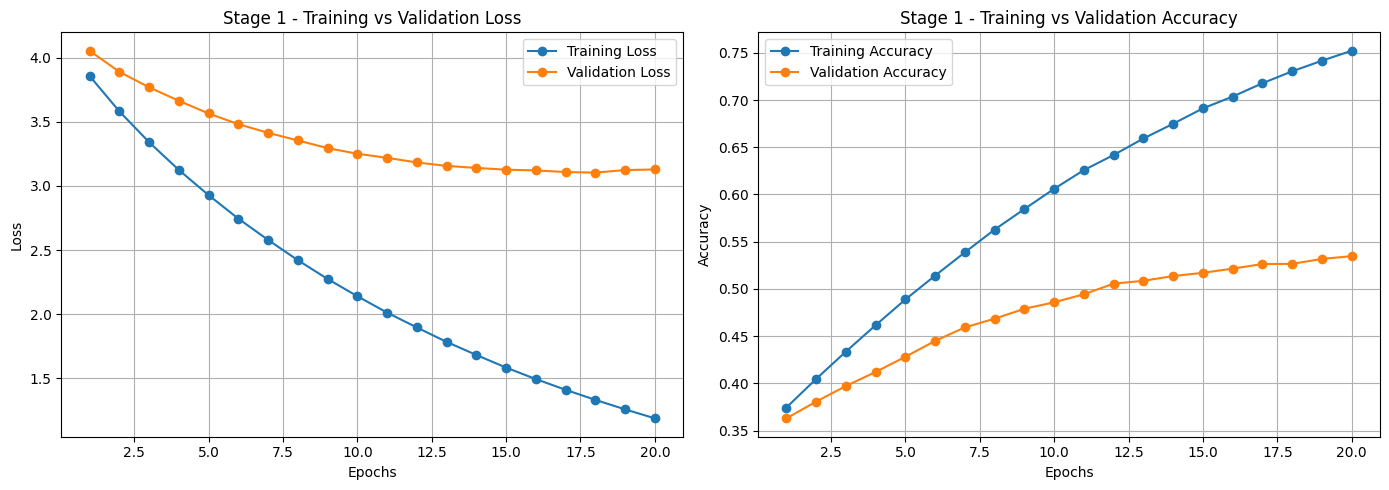

In [33]:

import matplotlib.pyplot as plt

# Stage 1 training history
train_loss = history_stage1.history["loss"]
val_loss = history_stage1.history["val_loss"]

train_acc = history_stage1.history["masked_accuracy"]
val_acc = history_stage1.history["val_masked_accuracy"]

epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(epochs_range, train_loss, marker="o",
         label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o",
         label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Stage 1 - Training vs Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(epochs_range, train_acc, marker="o",
         label="Training Accuracy")
plt.plot(epochs_range, val_acc, marker="o",
         label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Stage 1 - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(SAVE_DIR, "stage1_training_graph.png"),
    dpi=300
)

plt.show()


8: Stage 2 — Expanded dataset training

8.1 Load the best Stage 1 weights and configure Stage 2

In [31]:

import os
import keras
from keras.callbacks import EarlyStopping, ModelCheckpoint

# Confirm Stage 1 checkpoint exists
assert os.path.exists(STAGE1_PATH), "Stage 1 checkpoint not found!"

# Load the best Stage 1 weights
transformer.load_weights(STAGE1_PATH)

print("Best Stage 1 weights loaded successfully!")

# Use a fresh optimizer for Stage 2
transformer.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00005
    ),
    loss=masked_loss,
    metrics=[masked_accuracy]
)

# Save Stage 2 weights separately
STAGE2_PATH = os.path.join(
    SAVE_DIR,
    "stage2_best.weights.h5"
)

early_stopping_stage2 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint_stage2 = ModelCheckpoint(
    filepath=STAGE2_PATH,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

print("Stage 2 learning rate:",
      float(transformer.optimizer.learning_rate.numpy()))

print("Stage 2 checkpoint:", STAGE2_PATH)
print("Model parameters:", transformer.count_params())

Best Stage 1 weights loaded successfully!
Stage 2 learning rate: 4.999999873689376e-05
Stage 2 checkpoint: /content/drive/MyDrive/Transformer_Translation_Max/stage2_best.weights.h5
Model parameters: 6111384


8.2 Train Stage 2

In [32]:

history_stage2 = transformer.fit(
    stage2_train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping_stage2,
        checkpoint_stage2
    ]
)


Epoch 1/10
2518/2518 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 2.7170 - masked_accuracy: 0.5609
Epoch 1: val_loss improved from None to 2.43247, saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage2_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage2_best.weights.h5
2518/2518 ━━━━━━━━━━━━━━━━━━━━ 68s 22ms/step - loss: 2.5972 - masked_accuracy: 0.5710 - val_loss: 2.4325 - val_masked_accuracy: 0.5782
Epoch 2/10
2516/2518 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 2.3231 - masked_accuracy: 0.5993
Epoch 2: val_loss improved from 2.43247 to 2.24623, saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage2_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage2_best.weights.h5
2518/2518 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - loss: 2.2759 - masked_accuracy: 0.6050 - val_loss: 2.2462 - val_masked_accuracy: 0.5994
Epoch 3/10
2518/2518 ━━━━━━━━━━━━━━━━━━

8.3 Verify Stage 2 results

In [34]:

print("Stage 2 epochs completed:",
      len(history_stage2.history["loss"]))

print("Final training accuracy:",
      history_stage2.history["masked_accuracy"][-1])

print("Final validation accuracy:",
      history_stage2.history["val_masked_accuracy"][-1])

print("Best validation loss:",
      min(history_stage2.history["val_loss"]))

print("Stage 2 checkpoint saved:",
      os.path.exists(STAGE2_PATH))


Stage 2 epochs completed: 10
Final training accuracy: 0.7118061780929565
Final validation accuracy: 0.6630914807319641
Best validation loss: 1.734387993812561
Stage 2 checkpoint saved: True


Stage 2 training visualization

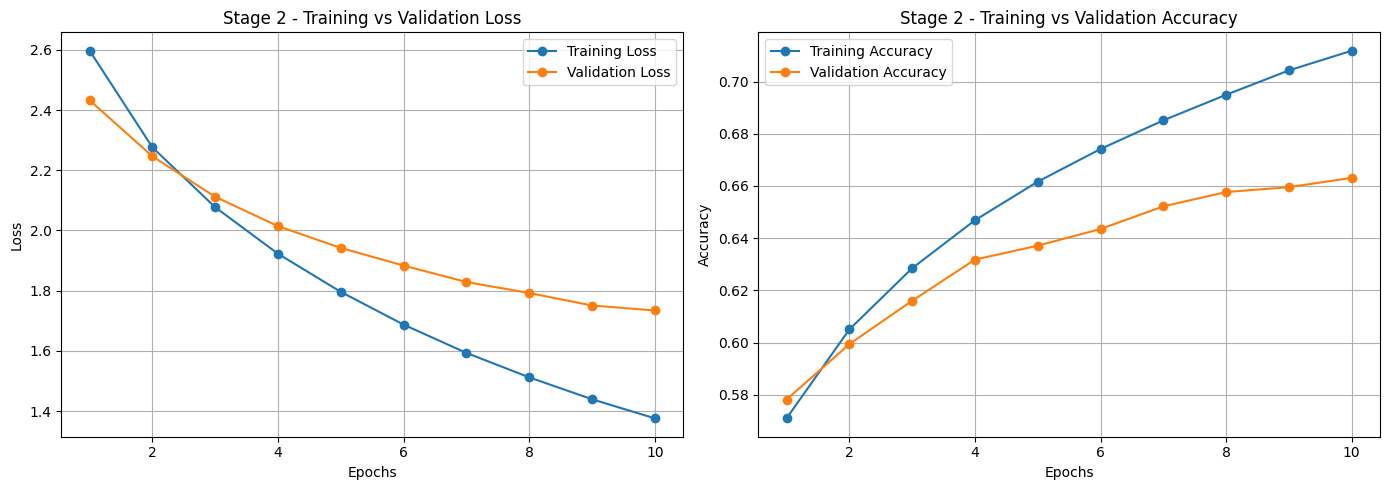

In [35]:

# Stage 2 training history
train_loss = history_stage2.history["loss"]
val_loss = history_stage2.history["val_loss"]

train_acc = history_stage2.history["masked_accuracy"]
val_acc = history_stage2.history["val_masked_accuracy"]

epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(epochs_range, train_loss, marker="o",
         label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o",
         label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Stage 2 - Training vs Validation Loss")
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(epochs_range, train_acc, marker="o",
         label="Training Accuracy")
plt.plot(epochs_range, val_acc, marker="o",
         label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Stage 2 - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(SAVE_DIR, "stage2_training_graph.png"),
    dpi=300
)

plt.show()


9: Stage 3 — Refinement training

9.1 Load the best Stage 2 weights and configure training

In [36]:

import os
import keras
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Confirm the Stage 2 checkpoint is saved
assert os.path.exists(STAGE2_PATH), "Stage 2 checkpoint not found!"

# Restore the best Stage 2 weights
transformer.load_weights(STAGE2_PATH)

print("Best Stage 2 weights loaded successfully!")

# Compile using a fresh optimizer at the Stage 3 learning rate
transformer.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00002
    ),
    loss=masked_loss,
    metrics=[masked_accuracy]
)

STAGE3_PATH = os.path.join(
    SAVE_DIR,
    "stage3_best.weights.h5"
)

early_stopping_stage3 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint_stage3 = ModelCheckpoint(
    filepath=STAGE3_PATH,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

lr_scheduler_stage3 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.000001,
    verbose=1
)

print("Stage 3 learning rate:",
      float(transformer.optimizer.learning_rate.numpy()))

print("Stage 3 checkpoint:", STAGE3_PATH)
print("Model parameters:", transformer.count_params())


Best Stage 2 weights loaded successfully!
Stage 3 learning rate: 1.9999999494757503e-05
Stage 3 checkpoint: /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5
Model parameters: 6111384


9.2 Train Stage 3

In [37]:

history_stage3 = transformer.fit(
    stage3_train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping_stage3,
        checkpoint_stage3,
        lr_scheduler_stage3
    ]
)


Epoch 1/10
2518/2518 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 1.3108 - masked_accuracy: 0.7229
Epoch 1: val_loss improved from None to 1.73141, saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5
2518/2518 ━━━━━━━━━━━━━━━━━━━━ 67s 21ms/step - loss: 1.3172 - masked_accuracy: 0.7228 - val_loss: 1.7314 - val_masked_accuracy: 0.6654 - learning_rate: 2.0000e-05
Epoch 2/10
2517/2518 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.2931 - masked_accuracy: 0.7258
Epoch 2: val_loss improved from 1.73141 to 1.72467, saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5
2518/2518 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - loss: 1.2913 - masked_accuracy: 0.7261 - val_loss: 1.7247 - val_masked_accuracy: 0.6659 - learning_

9.3 Visualize Stage 3 performance

Stage 3 best validation loss: 1.734387993812561
Stage 3 final validation accuracy: 0.6630914807319641
Stage 3 checkpoint saved: True


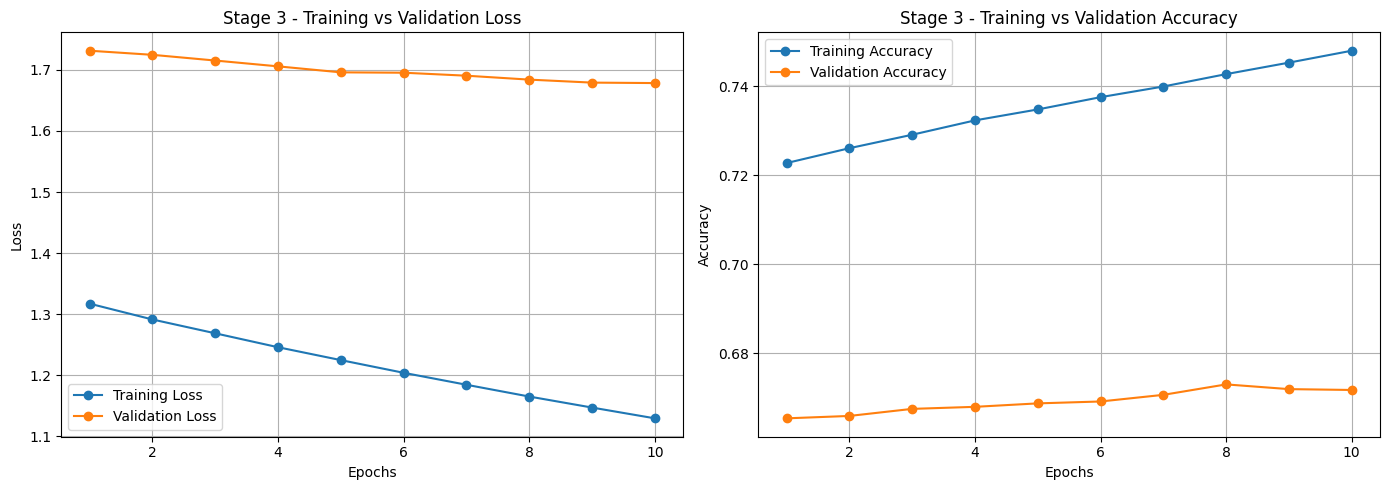

In [38]:

print("Stage 3 best validation loss:", min(val_loss))
print("Stage 3 final validation accuracy:", val_acc[-1])
print("Stage 3 checkpoint saved:", os.path.exists(STAGE3_PATH))

import matplotlib.pyplot as plt

train_loss = history_stage3.history["loss"]
val_loss = history_stage3.history["val_loss"]

train_acc = history_stage3.history["masked_accuracy"]
val_acc = history_stage3.history["val_masked_accuracy"]

epochs_range = range(1, len(train_loss) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_loss, marker="o", label="Training Loss")
plt.plot(epochs_range, val_loss, marker="o", label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Stage 3 - Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_acc, marker="o", label="Training Accuracy")
plt.plot(epochs_range, val_acc, marker="o", label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Stage 3 - Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(
    os.path.join(SAVE_DIR, "stage3_training_graph.png"),
    dpi=300
)
plt.show()


10: Evaluate the final Transformer

In [39]:

import os

assert os.path.exists(STAGE3_PATH), "Stage 3 checkpoint not found!"

# Load the best Stage 3 weights
transformer.load_weights(STAGE3_PATH)

print("Best Stage 3 weights loaded successfully!")
print("Model parameters:", transformer.count_params())
print("Checkpoint:", STAGE3_PATH)


Best Stage 3 weights loaded successfully!
Model parameters: 6111384
Checkpoint: /content/drive/MyDrive/Transformer_Translation_Max/stage3_best.weights.h5


10.2: Generate translations

In [40]:

import numpy as np

# Convert French token IDs back to words
french_vocab = target_vectorization.get_vocabulary()
index_to_word = dict(enumerate(french_vocab))

def translate_sentence(input_sentence):

    # Tokenize English sentence
    tokenized_input = source_vectorization(
        [input_sentence]
    )

    # Start decoder generation
    decoded_sentence = "[start]"

    for i in range(sequence_length):

        # Tokenize generated French text
        tokenized_target = target_vectorization(
            [decoded_sentence]
        )[:, :-1]

        # Predict next token
        predictions = transformer(
            {
                "encoder_inputs": tokenized_input,
                "decoder_inputs": tokenized_target
            },
            training=False
        )

        # Select highest-probability token
        sampled_token_index = int(
            np.argmax(predictions[0, i, :])
        )

        sampled_token = index_to_word[sampled_token_index]

        # Stop generation at end token
        if sampled_token == "[end]":
            break

        # Avoid padding and unknown tokens
        if sampled_token in ("", "[UNK]"):
            break

        decoded_sentence += " " + sampled_token

    return decoded_sentence.replace(
        "[start]", ""
    ).strip()

print("Translation function created successfully!")


Translation function created successfully!


10.3: Test your model

In [41]:

test_sentences = [
    "Hello.",
    "How are you?",
    "I am happy.",
    "I love you.",
    "Where are you going?",
    "Thank you.",
    "I am a student.",
    "Good morning.",
    "What is your name?",
    "I like learning."
]

print("English to French Translation\n")

for sentence in test_sentences:
    translation = translate_sentence(sentence)

    print("English:", sentence)
    print("French :", translation)
    print("-" * 45)


English to French Translation

English: Hello.
French : bonjour
---------------------------------------------
English: How are you?
French : comment estu
---------------------------------------------
English: I am happy.
French : je suis heureux
---------------------------------------------
English: I love you.
French : je vous aime
---------------------------------------------
English: Where are you going?
French : où allezvous
---------------------------------------------
English: Thank you.
French : merci
---------------------------------------------
English: I am a student.
French : je suis étudiant
---------------------------------------------
English: Good morning.
French : bon matin
---------------------------------------------
English: What is your name?
French : comment sappelle ton nom
---------------------------------------------
English: I like learning.
French : jaime apprendre
---------------------------------------------


11: Calculate BLEU on the test dataset

11.1 Install SacreBLEU

In [42]:

!pip -q install sacrebleu


11.2 Evaluate the complete test set

In [43]:

import sacrebleu
import re
import string

def normalize_for_bleu(text):
    text = text.replace("[start]", "").replace("[end]", "")
    text = text.lower()

    strip_chars = string.punctuation + "¿"
    strip_chars = strip_chars.replace("[", "").replace("]", "")

    text = re.sub(
        f"[{re.escape(strip_chars)}]",
        "",
        text
    )

    text = re.sub(r"\s+", " ", text)

    return text.strip()

references = []
predictions = []

for i, (english, french) in enumerate(test_pairs):

    predicted = translate_sentence(english)

    predictions.append(normalize_for_bleu(predicted))
    references.append(normalize_for_bleu(french))

    if (i + 1) % 500 == 0:
        print(f"Evaluated {i + 1}/{len(test_pairs)} sentences")

bleu = sacrebleu.corpus_bleu(
    predictions,
    [references],
    tokenize="13a"
)

print("\nFinal Test BLEU:", round(bleu.score, 2))
print("Total evaluated sentences:", len(predictions))

print("\nSample translations:\n")

for i in range(5):
    print("English  :", test_pairs[i][0])
    print("Reference:", references[i])
    print("Predicted:", predictions[i])
    print("-" * 45)


Evaluated 500/3000 sentences
Evaluated 1000/3000 sentences
Evaluated 1500/3000 sentences
Evaluated 2000/3000 sentences
Evaluated 2500/3000 sentences
Evaluated 3000/3000 sentences

Final Test BLEU: 32.66
Total evaluated sentences: 3000

Sample translations:

English  : The dog should be on a chain.
Reference: le chien devrait être attaché
Predicted: le chien devrait être une tronçonneuse
---------------------------------------------
English  : She was almost hit by a car.
Reference: elle a presque été heurtée par une voiture
Predicted: elle était presque heurté par une voiture
---------------------------------------------
English  : It's starting now.
Reference: ça commence
Predicted: cest démarrer maintenant
---------------------------------------------
English  : We were all alone.
Reference: nous étions tout seuls
Predicted: nous étions tous seuls
---------------------------------------------
English  : We were all alone.
Reference: nous étions toutes seules
Predicted: nous étions to